# 🧠 Week 9 Homework: Build and Improve a Neural Network

## 📌 Project: Predicting Breast Cancer Diagnosis

### 📝 Description

In this homework, you will use a real dataset included with **scikit-learn** to build a neural network that classifies tumors as:

- **Malignant**
- **Benign**

You will practice the complete neural-network workflow you learned in class:

**Load data → Explore data → Split data → Scale features → Build a neural network → Train → Validate → Evaluate → Improve**

### ⏱️ Estimated Time

**45–60 minutes**

### 🎯 Learning Goals

By the end of this homework, you should be able to:

- Identify **features** and **labels**
- Explain why neural-network inputs often need to be **scaled**
- Create a neural network with an **input layer, hidden layers, and an output layer**
- Explain **epochs**, **batch size**, **loss**, and **validation data**
- Plot training and validation performance
- Evaluate a neural network on unseen test data
- Experiment with the number of neurons or layers
- Recognize possible signs of **overfitting**

> **Important:** This is an educational machine-learning exercise. The model in this notebook is **not** a medical diagnostic tool and should never be used to make real medical decisions.


## 💡 Before You Start

You have already learned that an artificial neuron uses:

- **Inputs** — information entering the neuron
- **Weights** — how strongly each input affects the neuron
- **Bias** — an adjustable value
- **Activation function** — transforms the neuron's output

During training, the neural network repeatedly:

1. Makes predictions using **forward propagation**
2. Measures its error using a **loss function**
3. Adjusts its weights and biases
4. Repeats the process for many **epochs**

In this homework, **TensorFlow/Keras** performs the difficult calculations for us. Your job is to build the model correctly and understand the results.


# 1️⃣ Import the Libraries

We will use:

- `pandas` — organize and inspect the data
- `matplotlib` — create graphs
- `scikit-learn` — load data, split data, scale features, and evaluate predictions
- `TensorFlow/Keras` — build and train the neural network

Run the cell below.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

# Setting random seeds helps make results more repeatable.
np.random.seed(42)
tf.random.set_seed(42)
tf.keras.utils.set_random_seed(42)
tf.config.experimental.enable_op_determinism()

print("TensorFlow version:", tf.__version__)


I0000 00:00:1793495722.300877    6573 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


I0000 00:00:1793495723.747392    6573 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


TensorFlow version: 2.21.0


# 2️⃣ Load and Explore the Dataset

The dataset contains measurements calculated from images of breast tumor cells.

Each row represents one sample.

The dataset includes:

- **30 numeric features**
- A **target label**
- Two possible classes:
  - `0 = malignant`
  - `1 = benign`

Run the next cell to load the dataset.


In [ ]:
data = load_breast_cancer()

# X contains the input features.
X = data.data

# y contains the labels.
y = data.target

# Create a DataFrame so the data is easier to inspect.
df = pd.DataFrame(X, columns=data.feature_names)
df["diagnosis"] = [data.target_names[label] for label in y]

print(df.head())


   mean radius  mean texture  mean perimeter  mean area  mean smoothness  \
0        17.99         10.38          122.80     1001.0          0.11840   
1        20.57         17.77          132.90     1326.0          0.08474   
2        19.69         21.25          130.00     1203.0          0.10960   
3        11.42         20.38           77.58      386.1          0.14250   
4        20.29         14.34          135.10     1297.0          0.10030   

   mean compactness  mean concavity  mean concave points  mean symmetry  \
0           0.27760          0.3001              0.14710         0.2419   
1           0.07864          0.0869              0.07017         0.1812   
2           0.15990          0.1974              0.12790         0.2069   
3           0.28390          0.2414              0.10520         0.2597   
4           0.13280          0.1980              0.10430         0.1809   

   mean fractal dimension  ...  worst texture  worst perimeter  worst area  \
0             

## 🔍 Explore the Dataset

Run the cell below, then answer the questions.

### Questions

1. How many samples are in the dataset?
2. How many input features are there?
3. What are the two target classes?
4. Which class has more samples?


In [ ]:
print("Dataset shape:", X.shape)
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Target classes:", data.target_names)

print("\nClass counts:")
print(df["diagnosis"].value_counts())


Dataset shape: (569, 30)
Number of samples: 569
Number of features: 30
Target classes: ['malignant' 'benign']

Class counts:
diagnosis
benign       357
malignant    212
Name: count, dtype: int64


### ✍️ Your Answers

Write your answers below by editing this Markdown cell.

1. Number of samples: **569**
2. Number of features: **30**
3. Target classes: **malignant** and **benign**
4. Class with more samples: **benign** (357 samples vs. 212 malignant)


# 3️⃣ Split the Data

A good machine-learning experiment should not train and test on the same data.

We will create three groups:

| Dataset | Purpose |
|---|---|
| **Training set** | Used to learn the weights and biases |
| **Validation set** | Used to monitor the model during training |
| **Test set** | Used only at the end for final evaluation |

We will use approximately:

- **60% training**
- **20% validation**
- **20% testing**

Run the cell below.


In [ ]:
# First, reserve 20% of the full dataset for final testing.
X_train_full, X_test, y_train_full, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Then take 25% of the remaining 80% for validation.
# 25% of 80% = 20% of the full dataset.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full,
    y_train_full,
    test_size=0.25,
    random_state=42,
    stratify=y_train_full
)

print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))
print("Test samples:", len(X_test))


Training samples: 341
Validation samples: 114
Test samples: 114


## 🧠 Check Your Understanding

Why do we keep the **test set** separate until the end?

Write 1–2 sentences:

**YOUR ANSWER:** We keep the test set separate so the model is evaluated on data it has never seen during training or tuning. This gives us an honest estimate of how well the model will perform on new, real-world data.


# 4️⃣ Scale the Features

Neural networks usually learn better when input features have similar numerical scales.

For example:

- One feature might have values around `0.1`
- Another might have values around `1000`

Large differences in scale can make training harder.

We will use `StandardScaler`.

### Important Rule

We fit the scaler using **training data only**.

Then we use the same scaler to transform:

- Training data
- Validation data
- Test data

This prevents information from the validation or test set from leaking into training.


In [ ]:
scaler = StandardScaler()

# Learn the scaling values using ONLY the training data.
X_train_scaled = scaler.fit_transform(X_train)

# Apply the same scaling to validation and test data.
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print("First sample BEFORE scaling:")
print(X_train[0][:5])

print("\nFirst sample AFTER scaling:")
print(X_train_scaled[0][:5])


First sample BEFORE scaling:
[9.676e+00 1.314e+01 6.412e+01 2.725e+02 1.255e-01]

First sample AFTER scaling:
[-1.22811113 -1.33644026 -1.11371297 -1.06103504  2.1428203 ]


# 5️⃣ Build Your Neural Network

Now you will create the model.

Our starting architecture will be:

**30 inputs → 16 hidden neurons → 8 hidden neurons → 1 output**

### Hidden Layers

We use the **ReLU** activation function:

```python
activation="relu"
```

### Output Layer

This is a **binary classification** problem because there are two possible classes.

Therefore, the output layer has:

- **1 neuron**
- **sigmoid activation**

Sigmoid produces a value between `0` and `1`.

For this dataset:

- A value closer to `0` means the model leans toward **malignant**
- A value closer to `1` means the model leans toward **benign**


In [ ]:
# TODO: Build the neural network.
#
# Follow this structure:
# 1. Input shape = number of features
# 2. First hidden layer = 16 neurons with ReLU
# 3. Second hidden layer = 8 neurons with ReLU
# 4. Output layer = 1 neuron with sigmoid
#
# Hint:
# model = keras.Sequential([
#     keras.Input(shape=(... ,)),
#     layers.Dense(..., activation="..."),
#     ...
# ])

model = keras.Sequential([
    keras.Input(shape=(X_train_scaled.shape[1],)),
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(1, activation="sigmoid")
])

model.summary()


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 16)             │           496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 641 (2.50 KB)

 Trainable params: 641 (2.50 KB)

 Non-trainable params: 0 (0.00 B)

## ✅ Architecture Check

After completing the previous cell, `model.summary()` should help you answer:

1. How many hidden layers does your model have?
2. How many neurons are in each hidden layer?
3. Why does the output layer contain only **1 neuron**?

Write your answers below.

1. Hidden layers: **2**
2. Hidden neurons: **16 in the first hidden layer, 8 in the second**
3. Why one output neuron? **Because this is binary classification (malignant vs. benign), a single sigmoid neuron outputs one probability between 0 and 1, which is enough to distinguish between the two classes.**


# 6️⃣ Compile the Model

Before training, Keras needs three important instructions.

### Optimizer

We will use:

```python
optimizer="adam"
```

The optimizer helps update the weights and biases.

### Loss Function

Because this is binary classification, use:

```python
loss="binary_crossentropy"
```

The loss measures how wrong the model's predictions are.

### Metric

We will monitor:

```python
metrics=["accuracy"]
```

### ✏️ Your Task

Complete the code below.


In [ ]:
# TODO: Compile the model.

# Hint:
# model.compile(
#     optimizer="...",
#     loss="...",
#     metrics=["..."]
# )

model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)


# 7️⃣ Train the Neural Network

We will use:

- **40 epochs**
- **Batch size = 16**
- Training data
- Validation data

### Vocabulary Review

**Epoch:** one complete pass through the training dataset.

**Batch size:** the number of samples processed before the model updates its weights.

**Validation data:** data used to check how well the model performs during training.

### ✏️ Your Task

Complete the training code below.


In [ ]:
# TODO: Train the model.

# Hint:
#
# history = model.fit(
#     X_train_scaled,
#     y_train,
#     validation_data=(X_val_scaled, y_val),
#     epochs=...,
#     batch_size=...,
#     verbose=0
# )

history = model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=40,
    batch_size=16,
    verbose=0
)


# 8️⃣ Plot Training and Validation Accuracy

A graph makes it easier to see how the model learns.

### What to Look For

A healthy training process often shows:

- Training accuracy increasing
- Validation accuracy increasing
- Training and validation accuracy staying reasonably close

If training accuracy keeps increasing while validation accuracy becomes worse, the model may be **overfitting**.

### ✏️ Your Task

Complete the two missing lines.


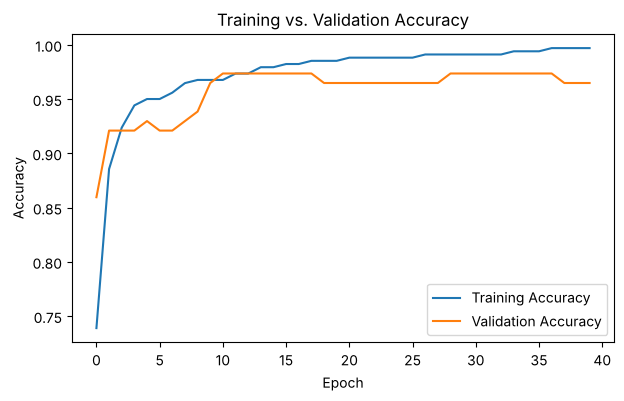

Final training accuracy: 0.997
Final validation accuracy: 0.965


In [ ]:
# TODO: Plot training and validation accuracy.

plt.figure(figsize=(7, 4))

plt.plot(history.history["accuracy"], label="Training Accuracy")
plt.plot(history.history["val_accuracy"], label="Validation Accuracy")

plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.title("Training vs. Validation Accuracy")
plt.legend()
plt.show()


print("Final training accuracy:", round(history.history["accuracy"][-1], 3))
print("Final validation accuracy:", round(history.history["val_accuracy"][-1], 3))

## 📈 Interpret the Accuracy Graph

Answer the following questions.

1. Did training accuracy generally improve?
2. Did validation accuracy generally improve?
3. Are the training and validation curves close together?
4. Do you see possible signs of overfitting?

Write 2–4 sentences:

**YOUR ANSWER:** Yes, training accuracy improved quickly in the first 10 epochs and kept rising slowly to about 99.7%. Validation accuracy also improved, reaching about 97% around epoch 10, then leveled off around 96.5–97%. The two curves stay fairly close (a gap of about 3 percentage points), so there is no strong overfitting. There is a slight early sign, though: after about epoch 10, training accuracy keeps climbing while validation accuracy stops improving.

# 9️⃣ Plot Training and Validation Loss

Remember:

- **Lower loss is better**
- Training loss should usually decrease
- Validation loss helps us see how well learning transfers to unseen data

Complete the missing lines.


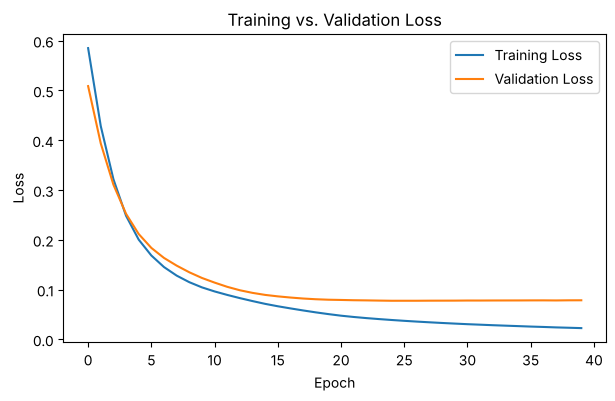

Final training loss: 0.023
Final validation loss: 0.078


In [ ]:
# TODO: Plot training and validation loss.

plt.figure(figsize=(7, 4))

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")

plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training vs. Validation Loss")
plt.legend()
plt.show()


print("Final training loss:", round(history.history["loss"][-1], 3))
print("Final validation loss:", round(history.history["val_loss"][-1], 3))

# 🔟 Evaluate the Model on the Test Set

The model has never used the test set for learning.

Now we can use it for our final evaluation.

### ✏️ Your Task

Use:

```python
model.evaluate(...)
```

with the **scaled test features** and **test labels**.


In [ ]:
# TODO: Evaluate your model.

# Hint:
# test_loss, test_accuracy = model.evaluate(
#     ...,
#     ...,
#     verbose=0
# )

test_loss, test_accuracy = model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Test loss:", round(test_loss, 3))
print("Test accuracy:", round(test_accuracy, 3))


Test loss: 0.106
Test accuracy: 0.956


## 💬 Test Result

Record your result.

**Test accuracy:** 0.956 (95.6%), test loss 0.106

Then answer:

**Is the test accuracy reasonably close to the training and validation accuracy? What does that tell you?**

**YOUR ANSWER:** Yes. The test accuracy (95.6%) is close to the final validation accuracy (96.5%) and a little below the training accuracy (99.7%). This tells me the model generalizes well to new data it has never seen, and is not badly overfitting.

# 1️⃣1️⃣ Make Predictions

For binary classification, the sigmoid output is a number between `0` and `1`.

We can turn that probability into a class:

```python
probability >= 0.5  → class 1
probability < 0.5   → class 0
```

Complete the cell below.


In [ ]:
# TODO: Generate prediction probabilities for the test set.

# Hint:
# probabilities = model.predict(X_test_scaled, verbose=0).flatten()

probabilities = model.predict(X_test_scaled, verbose=0).flatten()

predicted_classes = (probabilities >= 0.5).astype(int)

for i in range(10):
    print(
        f"Sample {i + 1}:",
        "Probability =", round(probabilities[i], 3),
        "| Predicted =", data.target_names[predicted_classes[i]],
        "| Actual =", data.target_names[y_test[i]]
    )


Sample 1: Probability = 0.0 | Predicted = malignant | Actual = malignant
Sample 2: Probability = 1.0 | Predicted = benign | Actual = benign
Sample 3: Probability = 0.0 | Predicted = malignant | Actual = malignant
Sample 4: Probability = 0.566 | Predicted = benign | Actual = benign
Sample 5: Probability = 0.0 | Predicted = malignant | Actual = malignant
Sample 6: Probability = 0.996 | Predicted = benign | Actual = benign
Sample 7: Probability = 1.0 | Predicted = benign | Actual = benign
Sample 8: Probability = 0.0 | Predicted = malignant | Actual = malignant
Sample 9: Probability = 0.0 | Predicted = malignant | Actual = malignant
Sample 10: Probability = 0.0 | Predicted = malignant | Actual = malignant


# 1️⃣2️⃣ Create a Confusion Matrix

Accuracy gives one overall number.

A **confusion matrix** gives more detail by showing which classes were predicted correctly and which were confused.

Run this step after you have created `predicted_classes`.


[[41  1]
 [ 4 68]]


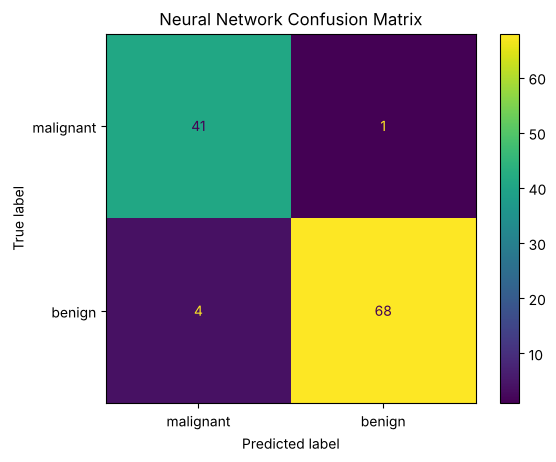

In [ ]:
# TODO: Create the confusion matrix.

# Hint:
# cm = confusion_matrix(y_test, predicted_classes)

cm = confusion_matrix(y_test, predicted_classes)
print(cm)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=data.target_names
)

display.plot()
plt.title("Neural Network Confusion Matrix")
plt.show()


## 🔍 Analyze the Confusion Matrix

Answer:

1. How many malignant samples were classified correctly?
2. How many benign samples were classified correctly?
3. How many total mistakes did the model make?
4. Why is it useful to look at a confusion matrix instead of accuracy alone?

**YOUR ANSWER:**
1. **41** malignant samples were classified correctly (out of 42).
2. **68** benign samples were classified correctly (out of 72).
3. The model made **5** total mistakes: 1 malignant tumor predicted as benign, and 4 benign tumors predicted as malignant.
4. A confusion matrix shows *which* classes get confused with each other, not just the overall percentage correct. This is especially important when misclassifying one class is more costly than another.


# 1️⃣3️⃣ Experiment: Can You Improve the Network?

A neural network has many design choices.

Now change the architecture and compare the result with your original model.

Choose **ONE** experiment.

### Option A — More Neurons

Change:

```python
16 → 32 neurons
```

in the first hidden layer.

### Option B — Add Another Hidden Layer

Add:

```python
layers.Dense(4, activation="relu")
```

before the output layer.

### Option C — Smaller Network

Try:

```python
8 neurons → 4 neurons
```

for the two hidden layers.

### Important

Keep the following the same so your comparison is fair:

- Same training data
- Same validation data
- Same test data
- Same number of epochs
- Same batch size


In [ ]:
# TODO: Create your experimental model.

experiment_model = keras.Sequential([
    keras.Input(shape=(X_train_scaled.shape[1],)),

    # Option B: Add another hidden layer with 4 neurons.
    layers.Dense(16, activation="relu"),
    layers.Dense(8, activation="relu"),
    layers.Dense(4, activation="relu"),

    layers.Dense(1, activation="sigmoid")
])

experiment_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

experiment_history = experiment_model.fit(
    X_train_scaled,
    y_train,
    validation_data=(X_val_scaled, y_val),
    epochs=40,
    batch_size=16,
    verbose=0
)

experiment_loss, experiment_accuracy = experiment_model.evaluate(
    X_test_scaled,
    y_test,
    verbose=0
)

print("Experiment test accuracy:", round(experiment_accuracy, 3))


Experiment test accuracy: 0.939


## 🧪 Compare Your Models

Complete the table.

| Model | Hidden-Layer Design | Test Accuracy |
|---|---|---|
| Original model | 16 neurons → 8 neurons | 0.956 |
| Experimental model | 16 → 8 → 4 neurons (extra hidden layer) | 0.939 |

### Questions

1. Which model performed better?
2. Was the difference large or small?
3. Did adding more neurons or layers automatically make the model better?
4. Why do you think neural-network experiments should be compared using the **same dataset split**?

**YOUR ANSWER:**
1. The **original model** performed better (95.6% vs. 93.9% test accuracy).
2. The difference was **small**, about 1.7 percentage points (2 more mistakes out of 114 test samples).
3. **No.** Adding an extra hidden layer made the model more complex but did not improve it; it actually did slightly worse. More layers or neurons do not automatically make a model better, especially on a small dataset.
4. Using the **same dataset split** makes the comparison fair, so any difference in accuracy comes from the change in architecture and not from the models being trained or tested on different data.

# 🧠 Final Reflection

Answer each question in 1–3 sentences.

### 1. What does a neural-network **weight** represent?

**YOUR ANSWER:** A weight represents how strongly an input feature influences a neuron's output. Larger weights mean that input has more impact on the prediction.

### 2. What is the purpose of an **activation function**?

**YOUR ANSWER:** An activation function transforms a neuron's weighted sum into a useful output, introducing non-linearity so the network can learn complex patterns. ReLU is used in hidden layers; sigmoid is used here to output a probability between 0 and 1.

### 3. What happens during **forward propagation**?

**YOUR ANSWER:** Input data passes through each layer of the network. Each neuron computes a weighted sum of its inputs, adds a bias, applies an activation function, and passes the result to the next layer until a final prediction is produced.

### 4. What does a **loss function** measure?

**YOUR ANSWER:** The loss function measures how far the model's predictions are from the true labels. Lower loss means the predictions are closer to correct.

### 5. What is an **epoch**?

**YOUR ANSWER:** An epoch is one complete pass through the entire training dataset. The model sees every training sample once per epoch.

### 6. Why do we use **validation data**?

**YOUR ANSWER:** Validation data lets us monitor how well the model performs on unseen data during training, without touching the test set. It helps detect overfitting and tune the model before final evaluation.

### 7. What is **overfitting**?

**YOUR ANSWER:** Overfitting happens when a model learns the training data too well, including noise and specific details, so it performs poorly on new data. Training accuracy stays high while validation accuracy drops.

### 8. In your own words, describe how a neural network learns.

**YOUR ANSWER:** The network starts with random weights and biases, makes predictions via forward propagation, measures error with the loss function, then adjusts weights and biases using the optimizer. This cycle repeats for many epochs until the model minimizes its error on the training data while hopefully generalizing to new data.


# ✅ Homework Completion Checklist

Before submitting your notebook, make sure you have:

- [x] Run the dataset exploration
- [x] Answered the dataset questions
- [x] Split the data into training, validation, and test sets
- [x] Scaled the features
- [x] Built the neural network
- [x] Compiled the model
- [x] Trained the model
- [x] Plotted accuracy
- [x] Plotted loss
- [x] Evaluated the test set
- [x] Made predictions
- [x] Created a confusion matrix
- [x] Completed one neural-network experiment
- [x] Compared the two models
- [x] Answered all final reflection questions
- [x] Run the notebook from top to bottom without unexpected errors

## 📌 Submission

Submit your completed `.ipynb` notebook according to your instructor's directions.

### Key Takeaway

A neural network learns by repeatedly:

**Make predictions → measure error → adjust weights and biases → repeat**

The goal is not simply to get the highest accuracy. A good AI student should also understand **how the model was trained, how it was evaluated, and what its limitations are**.
